**Necessary Packages**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import Flatten
from keras. layers import MaxPooling2D
from keras.layers import Dense
import numpy as np
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.datasets import fashion_mnist

**Load Dataset**

In [ ]:
# Download and load the Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Display dataset shapes
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [ ]:
# Normalize pixel values from [0, 255] to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [ ]:
# Add the channel dimension
# Before: (60000, 28, 28)
# After:  (60000, 28, 28, 1)

#Here, -1 means:Automatically determine the number of images in x_train.

#Since Fashion-MNIST has 60,000 training images, NumPy interprets it as:  -1 becomes 60000
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("CNN training input shape:", x_train.shape)
print("CNN testing input shape:", x_test.shape)

CNN training input shape: (60000, 28, 28, 1)
CNN testing input shape: (10000, 28, 28, 1)


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# Create the ImageDataGenerator for data augmentation
train_datagen = ImageDataGenerator(
    rotation_range=10,          # Randomly rotate images up to 10 degrees
    width_shift_range=0.1,      # Random horizontal shift
    height_shift_range=0.1,     # Random vertical shift
    zoom_range=0.1,             # Random zoom
    shear_range=0.1,            # Random shear transformation
    fill_mode="nearest"
)

# Test images should not be augmented
test_datagen = ImageDataGenerator()

batch_size = 32

#Create data generators
train_generator = train_datagen.flow(
    x_train,
    y_train,
    batch_size=batch_size,
    shuffle=True #This is used because the model should receive training images in a different random order during each epoch.
)

test_generator = test_datagen.flow(
    x_test,
    y_test,
    batch_size=batch_size,
    shuffle=False   #During testing, the order should remain unchanged.
)


**Building the CNN Model**

In [ ]:
model = models.Sequential()

# First Convolution Block
model.add(layers.Conv2D(
    filters=32,
    kernel_size=(3,3),
    activation='relu',
    input_shape=(28,28,1)
))
model.add(layers.MaxPooling2D((2,2)))

# Second Convolution Block
model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.MaxPooling2D((2,2)))

# Third Convolution Block
model.add(layers.Conv2D(128, (3,3), activation='relu'))
model.add(layers.MaxPooling2D((2,2)))
# Flatten Layer
model.add(layers.Flatten())

# Fully Connected Layers
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(0.5))

# Output Layer
model.add(layers.Dense(10, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


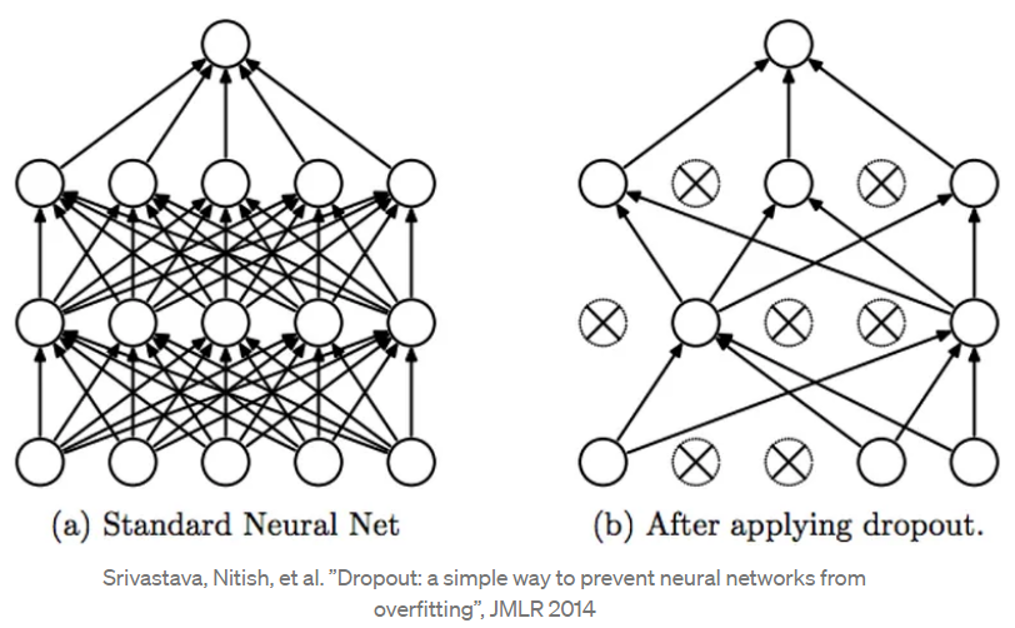

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=test_generator
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 35s 16ms/step - accuracy: 0.6855 - loss: 0.8407 - val_accuracy: 0.7695 - val_loss: 0.6133
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.7737 - loss: 0.6088 - val_accuracy: 0.8193 - val_loss: 0.4901
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.8045 - loss: 0.5312 - val_accuracy: 0.8382 - val_loss: 0.4347
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.8196 - loss: 0.4876 - val_accuracy: 0.8389 - val_loss: 0.4252
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.8288 - loss: 0.4654 - val_accuracy: 0.8432 - val_loss: 0.4101
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.8371 - loss: 0.4428 - val_accuracy: 0.8624 - val_loss: 0.3774
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.8437 - loss: 0.4304 - val_accuracy: 0.8602 - val_loss: 0.3772
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.8488 -

**Evaluate the model**

In [ ]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8625 - loss: 0.3623
Test Accuracy: 0.862500011920929
Test Loss: 0.3622617721557617


**If you are working on your own dataset**

# Define the paths
train_dir = '/content/drive/MyDrive/alzheimer dataset/train'

test_dir = '/content/drive/MyDrive/alzheimer dataset/test'

# Create an ImageDataGenerator object for data augmentation and preprocessing
train_datagen = ImageDataGenerator(

    rescale=1./255,
    shear_range=0.4,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    rotation_range=90,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

# Load the images and labels, ensuring grayscale (1 color channel)
train_generator = train_datagen.flow_from_directory(

    train_dir,
    target_size=(128, 128),        # Resize images to 128x128
    class_mode='categorical',
)

test_generator = test_datagen.flow_from_directory(
  
    test_dir,
    target_size=(128, 128),
    class_mode='categorical',

)

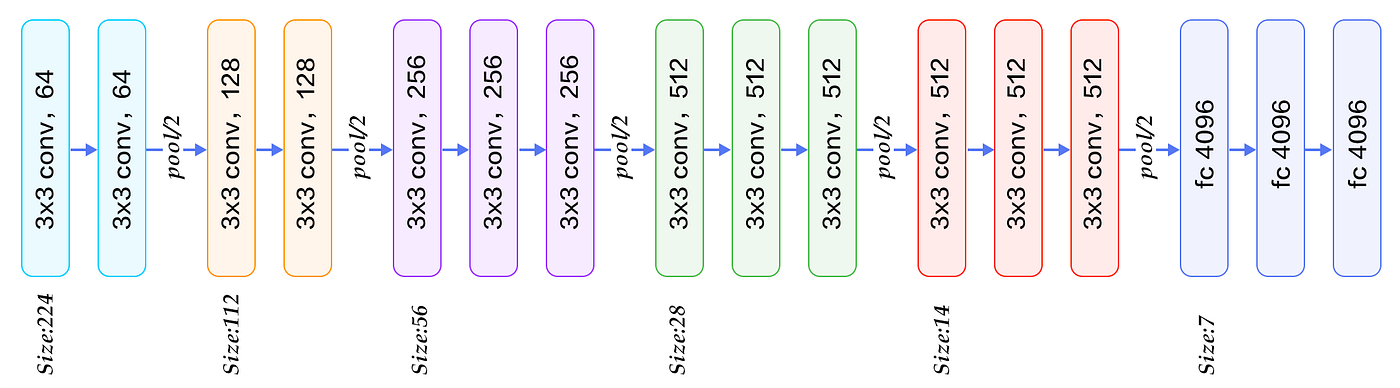

**Transfer Learning: VGG16**

In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Input, Concatenate, Flatten, Dense, Dropout, Resizing
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# 1. Input for grayscale image
input_tensor = Input(shape=(28, 28, 1))

# Add a Resizing layer to make the input compatible with VGG16 (e.g., 128x128)
resized_input = Resizing(128, 128)(input_tensor)

# 2. Convert grayscale → RGB by concatenation
# Apply concatenation to the resized input
input_tensor_rgb = Concatenate()([resized_input, resized_input, resized_input])
# Now shape becomes (128, 128, 3)

# 3. Load VGG16 WITHOUT top layers
vgg16 = VGG16(
    weights='imagenet',
    include_top=False,
    input_tensor=input_tensor_rgb
)

# 4. Create new model and add VGG as base
modelvgg16 = Sequential()
modelvgg16.add(vgg16)

# 5. Add custom classification head
modelvgg16.add(Flatten())
modelvgg16.add(Dense(256, activation='relu'))
modelvgg16.add(Dropout(0.5))
modelvgg16.add(Dense(128, activation='relu'))
modelvgg16.add(Dropout(0.5))

# Final output for 4 classes
modelvgg16.add(Dense(10, activation='softmax')) # Fashion-MNIST has 10 classes

# 6. Freeze VGG16 layers (transfer learning)
for layer in vgg16.layers:
    layer.trainable = False

# 7. Compile model
modelvgg16.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy', # Changed to sparse_categorical_crossentropy for integer labels
    metrics=['accuracy']
)

In [ ]:
modelvgg16.fit(train_generator,
               epochs=10,
    validation_data=test_generator
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 119s 59ms/step - accuracy: 0.6887 - loss: 0.8997 - val_accuracy: 0.8362 - val_loss: 0.4328
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 107s 57ms/step - accuracy: 0.8054 - loss: 0.5574 - val_accuracy: 0.8573 - val_loss: 0.3822
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 107s 57ms/step - accuracy: 0.8293 - loss: 0.4902 - val_accuracy: 0.8714 - val_loss: 0.3485
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 108s 57ms/step - accuracy: 0.8393 - loss: 0.4534 - val_accuracy: 0.8722 - val_loss: 0.3391
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 107s 57ms/step - accuracy: 0.8481 - loss: 0.4300 - val_accuracy: 0.8759 - val_loss: 0.3325
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 107s 57ms/step - accuracy: 0.8525 - loss: 0.4136 - val_accuracy: 0.8817 - val_loss: 0.3306
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 107s 57ms/step - accuracy: 0.8573 - loss: 0.4008 - val_accuracy: 0.8801 - val_loss: 0.3285
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 107s 57ms/step - accuracy: 

In [ ]:
test_loss, test_accuracy = modelvgg16.evaluate(test_generator)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.8854 - loss: 0.3096
Test Accuracy: 0.8853999972343445
Test Loss: 0.3096061646938324


**Transfer Learning: EfficientNetB0**

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Input, Concatenate, Dense, Dropout, Resizing, Rescaling, GlobalAveragePooling2D
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# 1. Original Fashion-MNIST grayscale input
input_tensor = Input(shape=(28, 28, 1))

# 2. Resize inside the model for EfficientNetB0
x = Resizing(96, 96)(input_tensor)

# 3. Convert grayscale image to RGB
x = Concatenate()([x, x, x])

# Shape: (96, 96, 1) → (96, 96, 3)

# 4. Fashion-MNIST was normalized to [0, 1].
# EfficientNetB0 preprocessing expects values in [0, 255].
x = Rescaling(255.0)(x)

# 5. Load pretrained EfficientNetB0
efficientnet_b0 = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_tensor=x
)

# 6. Freeze pretrained layers
for layer in efficientnet_b0.layers:
    layer.trainable = False

# 7. Add classification layers
x = GlobalAveragePooling2D()(efficientnet_b0.output)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)

x = Dense(128, activation="relu")(x)
x = Dropout(0.5)(x)

# Fashion-MNIST has 10 classes
output = Dense(10, activation="softmax")(x)

# 8. Create the complete model
model_efficientnet = Model(
    inputs=input_tensor,
    outputs=output
)

# 9. Compile
model_efficientnet.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
history_efficientnet = model_efficientnet.fit(
    train_generator,
    epochs=10,
    validation_data=test_generator
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.8661 - loss: 0.3736 - val_accuracy: 0.8846 - val_loss: 0.3204
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.8679 - loss: 0.3702 - val_accuracy: 0.8878 - val_loss: 0.3112
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.8691 - loss: 0.3627 - val_accuracy: 0.8875 - val_loss: 0.3136
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.8722 - loss: 0.3573 - val_accuracy: 0.8872 - val_loss: 0.3100
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.8703 - loss: 0.3583 - val_accuracy: 0.8877 - val_loss: 0.3109
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.8731 - loss: 0.3506 - val_accuracy: 0.8894 - val_loss: 0.3068
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.8745 - loss: 0.3500 - val_accuracy: 0.8906 - val_loss: 0.3042
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - accuracy: 0.8755 -

In [ ]:
test_loss, test_accuracy = model_efficientnet.evaluate(test_generator)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8926 - loss: 0.2976
Test Accuracy: 0.8925999999046326
Test Loss: 0.29763492941856384
